# OpenCV 培训大作业 · 奶蛙自动检测与标注系统

> RobotIC 算法组 · 新人培训第一讲 · **综合大作业**
> 覆盖必修讲义第 1～11 章的主要内容 ｜ 满分 90 分

---

## 背景

算法组要给《奶蛙圣殿巡行》的剧照做一个**自动标注工具**：
输入一张图，程序要能自动找到画面里的奶蛙、把它框出来、打上标签。

这段片子有个麻烦的地方 —— 奶蛙一会儿在亮堂堂的白底名画里，
一会儿又潜进昏暗的水下，**光照变化极大**。
你要做的，就是找一个"光照变了也照样认得出来"的办法。

## 交付要求

| 项 | 要求 |
| --- | --- |
| 代码 | 在 `OpenCV大作业_作答.ipynb` 上直接作答，**按顺序可运行** |
| 产物 | 题目要求的图片存到 `out/` 目录 |
| 小结 | 最后写一段 100~200 字的实验小结 |

> ⚠️ **三个硬性要求**
> 1. notebook 必须能**从头到尾一次跑通**（`Kernel → Restart & Run All`）
> 2. 不要删掉题目格子，只在 `# TODO` 处补代码
> 3. 产物文件名**按题目要求**命名，方便批改

## 评分总览

| 阶段 | 内容 | 对应章节 | 分值 |
| --- | --- | --- | --- |
| 一 | 素材体检与 ROI | 第 1、2 章 | 12 |
| 二 | **找到奶蛙的颜色**（核心） | 第 3、5、6 章 | 30 |
| 三 | 抠图与贴标 | 第 4 章 | 10 |
| 四 | 滤波去噪 | 第 8 章 | 10 |
| 五 | 摆正与标注 | 第 9、10 章 | 13 |
| 六 | 封装成类 | 第 11 章 | 15 |
| | | **合计** | **90** |

> 💡 开头有一段**公共代码**（导入 + 显示函数），已经给好了，直接跑。
> 后面的格子都能调用它里面的 `show()` 来并排看图。

---


## 公共代码（已给好，直接运行）


In [1]:
# ============ 公共代码：导入 + 显示函数（已给好，直接用） ============
import os
import time

import cv2
import numpy as np
import matplotlib.pyplot as plt

# 让 matplotlib 能显示中文（缺字体时会回退，不影响结果）
for _f in ['Noto Sans CJK SC', 'WenQuanYi Zen Hei', 'SimHei', 'DejaVu Sans']:
    try:
        matplotlib.font_manager.findfont(_f, fallback_to_default=False)
        plt.rcParams['font.sans-serif'] = [_f]
        break
    except Exception:
        continue
plt.rcParams['axes.unicode_minus'] = False

os.makedirs('out', exist_ok=True)


def show(*imgs, titles=None, gray_flags=None, figsize=(14, 4)):
    """并排显示多张图。灰度图请用 gray_flags=[..., True, ...] 标出来。"""
    n = len(imgs)
    titles = titles or [''] * n
    gray_flags = gray_flags if gray_flags is not None else [False] * n
    plt.figure(figsize=figsize)
    for i, (im, t, gf) in enumerate(zip(imgs, titles, gray_flags), 1):
        plt.subplot(1, n, i)
        if gf:
            plt.imshow(im, cmap='gray')
        else:
            plt.imshow(im[:, :, ::-1] if im.ndim == 3 else im)
        plt.title(t)
        plt.axis('off')
    plt.tight_layout()
    plt.show()


print('公共代码加载完成，OpenCV 版本：', cv2.__version__)

公共代码加载完成，OpenCV 版本： 4.10.0


---


## 阶段一 · 素材体检与 ROI（第 1、2 章）· 12 分

> 🎯 目标：拿到一张图，先搞清楚"它到底是什么"，再动手。

**任务 1.1（3 分）** 用三种模式读 `res/nl_think.png`，打印每种的 `shape / dtype / size`，
把结果填进下面的表（直接改这张表的 markdown 也行，写代码打印也行）：

| 读取模式 | shape | dtype |
| --- | --- | --- |
| `IMREAD_COLOR` | (655, 690, 3) | uint8 |
| `IMREAD_GRAYSCALE` | (655, 690) | uint8 |
| `IMREAD_UNCHANGED` | (655, 690, 3) | uint8 |

**任务 1.2（3 分）** 用 `IMREAD_UNCHANGED` 分别读 `res/rgb.png` 和 `res/nl_santa.png`，
打印它们的 shape，并回答：**为什么一个读出 4 通道，另一个读出 3 通道？**

**任务 1.3（3 分）** 读入 `res/nl_hd01.jpg`，把它**下半部分**裁出来（ROI），
打印原图与 ROI 的 shape、像素数，算出**像素数减少了百分之几**，把 ROI 存成 `out/hw1_roi.png`。

**任务 1.4（3 分）** ⚠️ 陷阱题：新建一个原图副本，取它下半部分当 ROI（**不要** `.copy()`），
在 ROI 上画一个实心红圆。然后打印**原图**对应位置的像素值。
回答：**原图被改了吗？为什么？** 怎么改才不会被改？（把结论写在下面的 markdown 格里）

In [2]:
# --- 任务 1.1 ---
for name, flag in [('IMREAD_COLOR', cv2.IMREAD_COLOR),
                   ('IMREAD_GRAYSCALE', cv2.IMREAD_GRAYSCALE),
                   ('IMREAD_UNCHANGED', cv2.IMREAD_UNCHANGED)]:
    im = cv2.imread('res/nl_think.png', flag)
    # TODO: 打印 name / shape / dtype
    print(im.shape, im.dtype, im.size)
    pass

(655, 690, 3) uint8 1355850
(655, 690) uint8 451950
(655, 690, 3) uint8 1355850


In [5]:
# --- 任务 1.2 ---
# TODO: 用 IMREAD_UNCHANGED 读这两张图，打印 shape，并回答为什么通道数不同
rgb_img     = cv2.imread("res/rgb.png", cv2.IMREAD_UNCHANGED)
nl_santa_img= cv2.imread("res/nl_santa.png", cv2.IMREAD_UNCHANGED)
print(rgb_img.shape)
print(nl_santa_img.shape)
# 答：一张有Alpha透明通道，一张没有,用cv2.IMREAD_UNCHANGED不会改变通道数

(359, 1284, 4)
(498, 500, 3)


In [8]:
# --- 任务 1.3 ---
img = cv2.imread('res/nl_hd01.jpg')
# TODO: 裁出下半部分，打印 shape / 像素数 / 减少比例，存成 out/hw1_roi.png
#   提示：切片是 img[行范围, 列范围]，行列对应 [y, x]
#   提示：像素数用 .size
h, w, c = img.shape
roi = img[h//2:,:]
print(img.shape)
print(roi.shape)
reduce = (img.size - roi.size) / img.size * 100
print("减少百分比：", str(reduce), "%")
# cv2.imwrite("out/hw1_roi.png", roi)

(1080, 1920, 3)
(540, 1920, 3)
减少百分比： 50.0 %


In [11]:
# --- 任务 1.4（陷阱题） ---
demo = img.copy()
# TODO: 取 demo 下半部分作为 roi（先不要 .copy()），在上面画一个实心红圆
# TODO: 打印 demo 在圆心处的像素值，观察原图有没有被改
#   画圆：cv2.circle(图, 圆心(x,y), 半径, 颜色BGR, -1)   ← -1 表示填充
h, w, c = demo.shape
roi = demo[h//2:, :]
# roi = demo[h//2:, :].copy() # 正确形式
cv2.circle(roi, (100,100), 100, (0, 0, 255), 5)
cv2.imshow("demo", demo)
cv2.waitKey(0)
cv2.destroyAllWindows()


**1.2 回答：**

*原图被改变了，因为roi是浅拷贝，只拷贝原图地址，对其的修改会作用到原图上*

**1.4 回答：**

*在结尾加上.copy()*

---


## 阶段二 · 找到奶蛙的颜色（第 3、5、6 章）· 30 分

> 🎯 目标：用 HSV 把奶蛙从背景里切出来 —— **这是整份大作业的核心**。
> 讲义里说过："赛场上一大半'识别不到目标'，根因就在这。"

**任务 2.1（4 分）** 读入 `res/nl_hd01.jpg`，转到 `HSV_FULL`，
打印下面 4 个坐标的 **BGR** 和 **HSV_FULL** 值，并指出哪一个是**奶蛙皮肤**、哪两个是**白色背景**：

| 坐标 (x, y) | BGR | HSV_FULL | 是什么 |
| --- | --- | --- | --- |
| (978, 546) | [133,166,185] | [27,72,185] | 奶蛙的肚子 |
| (757, 368) | [11,12,26] | [3,147,26] | 奶蛙的嘴巴 |
| (978, 73) | [247,247,247] | [0,0,247] | 白色背景 |
| (5, 5) | [255,255,255] | [0,0,255] | 白色背景 |

> ⚠️ 坐标是 `(x, y)`，但取像素要写 `img[y, x]` —— 别搞反。

**任务 2.2（8 分）** 用 `cv2.inRange` 把奶蛙皮肤分割出来：

1. 转到 `COLOR_BGR2HSV_FULL`
2. 用 `inRange` 卡出奶蛙的 H 区间（**自己根据 2.1 的采样结果定**）
3. 用**开运算**清理小白点
4. 把 mask 存成 `out/hw2_mask.png`，把抠出来的结果（原图 × mask）存成 `out/hw2_result.png`
5. 打印去噪前后前景占比的变化

**任务 2.3（4 分）** 用 `cv2.findContours` 找出 mask 里**面积最大**的连通块，
用 `cv2.boundingRect` 得到外接矩形，把框画在原图上存成 `out/hw2_bbox.png`，
并打印这个 bbox 的 `(x, y, w, h)`。

**任务 2.4（5 分）** 红色陷阱：读 `res/nl_santa.png`（圣诞帽是红的），
分别用 `0~14` **单独**、以及 `0~14` **加上** `243~255` 两段做红色分割，
打印两次得到的像素数，并解释**为什么要分两段**。

**任务 2.5（6 分）⭐ 压轴** 光照稳定性实验：

把 `res/nl_hd01.jpg` 整体乘以亮度系数 k（`k = 0.4 / 0.7 / 1.0 / 1.3`），
盯住奶蛙皮肤上 **(978, 546)** 这一个像素，观察它怎么变：

1. 在 `k = 1.0` 处标定两个阈值：
   - **BGR 区间**：该像素的 BGR 值 ±40
   - **HSV 区间**：H ±15，且 S ≥ 60、V ≥ 60
2. 把这**两组区间分别**拿去测 4 个亮度下的**同一个像素**，填表：

| 亮度 k | BGR 值 | H | S | V | BGR 阈值 | HSV 阈值 |
| --- | --- | --- | --- | --- | --- | --- |
| 0.4 | [53 66 74] | 27 | 72 | 185 | [13 26 34] ~ [ 93 106 114] | [12 60 60] ~ [ 42 255 255] |
| 0.7 | [ 93 116 129] | 27 | 72 | 185 | [53 76 89] ~ [133 156 169] | [12 60 60] ~ [ 42 255 255] |
| 1.0 | [133 166 185] | 27 | 72 | 185 | [ 93 126 145] ~ [173 206 225] | [12 60 60] ~ [ 42 255 255] |
| 1.3 | [172 215 240] | 27 | 72 | 185 | [132 175 200] ~ [212 255 255] | [12 60 60] ~ [ 42 255 255] |

3. **回答（写在下面 markdown 格里）**：哪个分量几乎不变？哪个分量变得最厉害？
   如果只按 BGR 卡阈值，换一个光照会怎样？

**任务 2.6（3 分）** 刻度陷阱：把 `res/nl_hd01.jpg` 转成 `0~1` 的 `float32`，乘以 1.5 提亮，
然后 ① **直接** `cv2.imwrite` 存一次；② 先转回 `0~255` 的 `uint8` 再存一次。
把两张都读回来打印均值，解释差异。

In [26]:
# --- 任务 2.1 ---
img = cv2.imread('res/nl_hd01.jpg')
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV_FULL)
# TODO: 打印这 4 个坐标的 BGR 和 HSV_FULL
#   注意取像素是 img[y, x]（先 y 后 x）
img_copy = img.copy()
points = [(978, 546), (757, 368), (978, 73), (5, 5)]
num = 1
for (x, y) in points:
    bgr_val = img[y, x]
    hsv_val = hsv[y, x]
    print("坐标:", str((x, y)), "BGR:", str(bgr_val), "HSV:", str(hsv_val))
    cv2.circle(img_copy, (x, y), 5, (0,0,255), -1)
    cv2.putText(img_copy, str(num), (x, y), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
    num += 1
cv2.imshow("img", img_copy)white_pixel_count = cv2.countNonZero(img)
cv2.waitKey(0)
cv2.destroyAllWindows()

SyntaxError: invalid syntax (3879086327.py, line 16)

In [8]:
# --- 任务 2.2 ---
# ★★★ 下面两行必须自己填（参考 2.1 的采样结果）★★★
LOWER = np.array([12, 8, 9])      # TODO: 奶蛙皮肤的 [H, S, V] 下限
UPPER = np.array([200, 255, 255])      # TODO: [H, S, V] 上限
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV_FULL)

img_range = cv2.inRange(img, LOWER, UPPER)
cv2.imshow("img_range", img_range)

# TODO: inRange 得到 mask
# TODO: 开运算去噪（结构元素用 np.ones((7,7), np.uint8)）
# TODO: 打印去噪前后前景占比
# TODO: 存 mask -> out/hw2_mask.png，抠图结果 -> out/hw2_result.png
#   抠图用 cv2.bitwise_and(img, img, mask=mask)
#   显示时别忘了 show(img, mask, result, titles=[...], gray_flags=[False, True, False])
dest1_count = cv2.countNonZero(img_range)
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))
closed_img = cv2.morphologyEx(img_range, cv2.MORPH_CLOSE, kernel)
dest2_count = cv2.countNonZero(closed_img)
dst = cv2.bitwise_and(img, img, mask = closed_img)

reduce1 = abs(dest1_count - img.size) / img.size * 100
reduce2 = abs(dest2_count - img.size) / img.size * 100
print("减少百分比：", str(reduce1), "%")
print("减少百分比：", str(reduce2), "%")

cv2.imshow("result", dst)
cv2.waitKey(0)
cv2.destroyAllWindows()

减少百分比： 89.16485018004116 %
减少百分比： 89.05338541666666 %


In [12]:
# --- 任务 2.3 ---
# TODO: findContours 找轮廓（注意 OpenCV 4.x 返回两个值）
# TODO: 按面积排序，取最大的一个
# TODO: boundingRect 拿外接矩形，打印 (x, y, w, h)
# TODO: 画框并存成 out/hw2_bbox.png
#   面积用 cv2.contourArea(c)，排序用 sorted(cnts, key=cv2.contourArea, reverse=True)
img_rectangle = img.copy()
contours, hierarchy = cv2.findContours(closed_img, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
sorted_contours = sorted(contours, key = cv2.contourArea, reverse = True)
max_contour = sorted_contours[0] if sorted_contours else None
x, y, w, h = cv2.boundingRect(max_contour)
cv2.rectangle(img_rectangle, (x, y), (x + w, y + h), (0, 255, 0), 2)
cv2.imshow("result", img_rectangle)
cv2.waitKey(0)
cv2.destroyAllWindows()
cv2.imwrite("out/hw2_bbox.png", img_rectangle)

True

In [17]:
# --- 任务 2.4（红色分两段） ---
santa = cv2.imread('res/nl_santa.png')
shsv = cv2.cvtColor(santa, cv2.COLOR_BGR2HSV_FULL)
# TODO: 只用 0~14 做一次红色 mask
# TODO: 再补上 243~255 两段相或
# TODO: 打印两次的像素数（mask.sum()/255），解释差别
LOWER1 = np.array([0, 50, 50])   ?
UPPER1 = np.array([14, 255, 255])
img_range1 = cv2.inRange(shsv, LOWER1, UPPER1)

LOWER2 = np.array([243, 50, 50])   
UPPER2 = np.array([255, 255, 255])  
img_range2 = cv2.inRange(shsv, LOWER2, UPPER2)

dst_red = cv2.bitwise_or(img_range1, img_range2, mask = None)

cv2.imshow("dst", dst_red)
cv2.imshow("origin", santa)

cv2.waitKey(0)
cv2.destroyAllWindows()

# 答：红色掩码在hsv色域中是断开的，需要进行人为拼接

In [21]:
# --- 任务 2.5 ⭐ 压轴：光照稳定性实验 ---
px = (978, 546)
base_px = img[px[1], px[0]].astype(int)
hsv0 = hsv[px[1], px[0]]
base_px_copy = base_px.copy()

'''
# 在 k=1.0 处标定两组阈值
b_lo = np.clip(base_px - 40, 0, 255).astype(np.uint8)      # BGR 区间下限
b_up = np.clip(base_px + 40, 0, 255).astype(np.uint8)      # BGR 区间上限
h_lo = np.array([max(int(hsv0[0]) - 15, 0), 60, 60])       # HSV 区间下限
h_up = np.array([int(hsv0[0]) + 15, 255, 255])             # HSV 区间上限

print(f'BGR 区间 {b_lo} ~ {b_up}')
print(f'HSV 区间 {h_lo} ~ {h_up}')
'''

# TODO: 对 k in [0.4, 0.7, 1.0, 1.3] 循环：
#   1) 整图乘 k（记得 np.clip 到 0~255 再 astype(np.uint8)）
#   2) 取 (978,546) 处的 BGR 和 HSV_FULL
#   3) 判断该像素是否落在 BGR 区间内、是否落在 HSV 区间内
#   4) 打印一行，填进上面的表

k_range = [0.4, 0.7, 1.0, 1.3]
for k in k_range:
    k_dst = k * base_px_copy
    k_hsv = hsv[px[1], px[0]]

    b_lo = np.clip(k_dst - 40, 0, 255).astype(np.uint8)      # BGR 区间下限
    b_up = np.clip(k_dst + 40, 0, 255).astype(np.uint8)      # BGR 区间上限
    b = np.array(k_dst).astype(np.uint8)
    h_lo = np.array([max(int(k_hsv[0]) - 15, 0), 60, 60])       # HSV 区间下限
    h_up = np.array([int(k_hsv[0]) + 15, 255, 255])             # HSV 区间上限
    h = np.array(k_hsv).astype(np.uint8)
[172 215 240]
    print(f"k:{k}")
    print(f'BGR 区间 {b_lo} ~ {b_up}')
    print(f'HSV 区间 {h_lo} ~ {h_up}')
    print(f"BGR:{b}")
    print(f"HSV:{h}")


k:0.4
BGR 区间 [13 26 34] ~ [ 93 106 114]
HSV 区间 [12 60 60] ~ [ 42 255 255]
BGR:[53 66 74]
HSV:[ 27  72 185]
k:0.7
BGR 区间 [53 76 89] ~ [133 156 169]
HSV 区间 [12 60 60] ~ [ 42 255 255]
BGR:[ 93 116 129]
HSV:[ 27  72 185]
k:1.0
BGR 区间 [ 93 126 145] ~ [173 206 225]
HSV 区间 [12 60 60] ~ [ 42 255 255]
BGR:[133 166 185]
HSV:[ 27  72 185]
k:1.3
BGR 区间 [132 175 200] ~ [212 255 255]
HSV 区间 [12 60 60] ~ [ 42 255 255]
BGR:[172 215 240]
HSV:[ 27  72 185]


In [25]:
# --- 任务 2.6（刻度陷阱） ---
fimg = img.astype(np.float32) / 255.0            # 变成 0~1
bright = np.clip(fimg * 1.5, 0, 1)
# TODO: ① 直接 cv2.imwrite 存一次 -> out/hw2_float_wrong.png
# TODO: ② 先 (bright*255).astype(np.uint8) 再存 -> out/hw2_float_right.png
# TODO: 两张都读回来打印均值，解释差异

cv2.imwrite("out/hw2_float_wrong.png", bright)
bright2 = (bright*255).astype(np.uint8)
cv2.imwrite("out/hw2_float_right.png", bright2)

img_wrong = cv2.imread("out/hw2_float_wrong.png")
img_right = cv2.imread("out/hw2_float_right.png")

mean_wrong = np.mean(img_wrong)
mean_right = np.mean(img_right)

print(f"mean_wrong:{mean_wrong}")
print(f"mean_right:{mean_right}")

mean_wrong:0.9543565136316873
mean_right:237.24420894418725


**2.5 回答（哪个分量稳定、哪个不稳、BGR 卡阈值会怎样）：**

*使用BGR识别，BGR随光照变化而偏移，目标容易超出区域。HSV更稳，HSV只有V量会变化*

**2.6 回答（为什么直接存会出问题）：**

*保存图片默认是uint8的形式，而原图是255的范围，转换过程会有损失*

---


## 阶段三 · 抠图与贴标（第 4 章）· 10 分

**任务 3.1（3 分）** 验证饱和加法与 NumPy 加法的区别：
造两个 `uint8` 的二维数组 `x = [[200, 200]]`、`y = [[100, 100]]`，
分别打印 `cv2.add(x, y)` 和 `x + y`，解释为什么结果不同。

**任务 3.2（7 分）** 把 `res/logo.png` 贴到 `res/nl_hd01.jpg` 的**右下角**，存成 `out/hw3_logo_paste.png`。

要求按经典四步做：

1. 在底图上取一块与 logo **等大**的 ROI
2. 把 logo 灰度化 + 阈值化，得到 logo 前景的掩膜 `mask`，再 `bitwise_not` 得到 `mask_inv`
3. 用 `mask_inv` 抠出 ROI 的背景部分，用 `mask` 抠出 logo 前景部分
4. 两部分相加，再放回原图 ROI

> ⚠️ 这个 logo 是 **白底 + 深色图案**。想清楚阈值化该用 `THRESH_BINARY` 还是
> `THRESH_BINARY_INV` —— 选错了会把底图那块涂白，logo 反而消失。

In [3]:
# --- 任务 3.1 ---
x = np.array([[200, 200]], np.uint8)
y = np.array([[100, 100]], np.uint8)
# TODO: 打印 cv2.add(x, y) 和 x + y，解释差别
#   提示：uint8 最大 255，300 存不下

add1 = x + y
add2 = cv2.add(x, y)

print(add1)
print(add2)

[[44 44]]
[[255 255]]


In [17]:
# --- 任务 3.2 ---
base = cv2.imread('res/nl_hd01.jpg')
logo = cv2.imread('res/logo.png')
lh0, lw0 = base.shape[:2]
lh, lw = logo.shape[:2]
print(f'底图 {base.shape}，logo {logo.shape}')

mask = np.zeros((lh0, lw0), dtype = np.uint8)


gray = cv2.cvtColor(logo, cv2.COLOR_BGR2GRAY)
ret, binary = cv2.threshold(gray, thresh = 127, maxval=255, type=cv2.THRESH_BINARY_INV)
mask[lh0 - lh:,lw0 - lw:] = binary

base[mask == 255] = [0, 0, 0]


cv2.imshow("logo", base)


cv2.waitKey(0)
cv2.destroyAllWindows()
cv2.imwrite("out/hw3_logo_paste.png", base)
# TODO 1: 取右下角等大 ROI
# roi = base[?, ?, ?, ?]

# mask[lh0 - lh:, lw0 - lw:] = 0

# mask_inv = ~mask

# TODO 2: 灰度化 + 阈值化得到 mask，再取反得到 mask_inv
#   先打印 logo 灰度的 min/max，判断该用 BINARY 还是 BINARY_INV

# cv2.imshow("logo", binary)


# cv2.waitKey(0)
# cv2.destroyAllWindows()
# TODO 3: 抠出背景 bg 和前景 fg
# bg = cv2.bitwise_and(roi, roi, mask=mask_inv)
# fg = cv2.bitwise_and(logo, logo, mask=mask)

# TODO 4: 相加后放回原图 ROI，存成 out/hw3_logo_paste.png


底图 (1080, 1920, 3)，logo (373, 801, 3)


True

**3.1 回答（两个结果分别是什么、为什么）：**

*add1 = [[44, 44]] add2 = [[255, 255]] 直接用+会超过255,打印时自动进行取余。add函数保证不会超出阈值*

---


## 阶段四 · 滤波去噪（第 8 章）· 10 分

**任务 4.1（4 分）** 给 `res/nl_classic1.jpg` 加 **3% 的椒盐噪声**
（黑白点各一半，用 `np.random.seed(42)` 保证可复现），
然后分别用**均值、高斯、中值**三种滤波（核都用 5×5）处理，
计算每种结果与**干净原图**的平均绝对差（`np.abs(差分).mean()`），
把三个数打印出来，指出哪个最干净。把对比图存成 `out/hw4_filter_compare.png`。

**任务 4.2（3 分）** 手算题：一个 3×3 邻域里，8 个像素是 100，1 个是白点 255。
分别算出**均值**和**中值**的结果，用这个例子解释**为什么中值滤波专治椒盐噪声**。

**任务 4.3（3 分）** 回答：**双边滤波**和上面三种有什么本质不同？它换来了什么、代价是什么？

In [22]:
# --- 任务 4.1 ---


def add_salt_pepper(image, ratio=0.03):
    """加椒盐噪声：一半黑点一半白点。"""
    noisy = image.copy()
    n = int(image.shape[0] * image.shape[1] * ratio)
    ys = np.random.randint(0, image.shape[0], n)
    xs = np.random.randint(0, image.shape[1], n)
    half = n // 2
    noisy[ys[:half], xs[:half]] = 0
    noisy[ys[half:], xs[half:]] = 255
    return noisy


np.random.seed(42)
scene = cv2.imread('res/nl_classic1.jpg')
noisy = add_salt_pepper(scene, 0.03)

# TODO: 分别用 cv2.blur / cv2.GaussianBlur / cv2.medianBlur（核 5x5）处理 noisy
# TODO: 打印每种结果与 scene 的平均绝对差
#   np.abs(结果.astype(np.int16) - scene.astype(np.int16)).mean()
#   ⚠️ 先转 int16 再相减，否则 uint8 相减会回绕
# TODO: 把 加噪图 / 均值 / 高斯 / 中值 横着拼起来存 out/hw4_filter_compare.png

blur_mean = cv2.blur(noisy, (5,5))
blur_gauss = cv2.GaussianBlur(noisy, (5,5), 0)
blur_median = cv2.medianBlur(noisy, 5)

def calc_mean(img1, img2):
    return np.abs(img1.astype(np.int16) - img2.astype(np.int16)).mean()

mean_mean = calc_mean(blur_mean, scene)
mean_gauss = calc_mean(blur_gauss, scene)
mean_median = calc_mean(blur_median, scene)

print(f'mean:{mean_mean}')
print(f'guassian:{mean_gauss}')
print(f'median:{mean_median}')

concat_img = np.hstack([noisy, blur_mean, blur_gauss, blur_median])
cv2.imwrite("out/hw4_filter_compare.png", concat_img)

mean:4.170131172839506
guassian:3.993438303755144
median:0.6752326067386831


True

**4.2 回答（手算过程）：**

*均质：117.22  椒盐噪点是极端突变噪点，用均值滤波会改变平均亮度，而中值滤波在卷积核中找中间值，由此来去除椒盐噪点*

**4.3 回答：**

*双边滤波对颜色突变非常敏感，可以将边缘两侧的图像进行平滑，方便后续二值化操作，但也损失一些特征*

---


## 阶段五 · 摆正与标注（第 9、10 章）· 13 分

**任务 5.1（4 分）** 把 `out/card.png` **逆时针旋转 30°**，存成 `out/hw5_rotate30.png`。
（提示：`cv2.getRotationMatrix2D(中心, 角度, 缩放)`，角度为正表示逆时针）

**任务 5.2（4 分）** 把 `res/nl_hd01.jpg` 缩放到**宽 640**（保持宽高比），
用 `cv2.INTER_AREA` 插值，打印缩放前后的 shape。
回答：**缩小图片时推荐用哪个插值方法？放大呢？**

**任务 5.3（5 分）** 在上一步缩放后的图上，把奶蛙**框出来并打上标签**：

- 用阶段二检测到的 bbox `(537, 13, 882, 1067)`（这是**原图**坐标，
  缩放后要一起乘 `640/1920`）
- 画一个绿色矩形框
- 在框内顶部写一行文字 `Nailong 92%`
- 存成 `out/hw5_annotate.png`


In [7]:
# --- 任务 5.1 ---
card = cv2.imread('out/card.png')
ch, cw = card.shape[:2]
# TODO: 构造旋转矩阵（中心用 (cw//2, ch//2)，角度 30，缩放 1.0）
# TODO: warpAffine 应用，存成 out/hw5_rotate30.png
M = cv2.getRotationMatrix2D((cw//2, ch//2), 30, 1.0)
rotated = cv2.warpAffine(card, M, (cw, ch)) 
# cv2.imshow("rotate_img", rotated)
# cv2.waitKey(0)
# cv2.destroyAllWindows()
cv2.imwrite('out/hw5_rotate30.png', rotated) 

True

In [9]:
# --- 任务 5.2 ---
img = cv2.imread('res/nl_hd01.jpg')
# TODO: 缩放到宽 640，保持宽高比，插值用 INTER_AREA
#   新高度 = int(640 * 原高 / 原宽)
# TODO: 打印缩放前后的 shape
h, w = img.shape[:2]
new_w = 640
new_h = int(new_w * h / w)
img_small = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_AREA)
print(f'缩放前 shape = {img.shape}  ({w}, {h})')
print(f'缩放后 shape = {img_small.shape}  ({new_w}, {new_h})')

缩放前 shape = (1080, 1920, 3)  (1920, 1080)
缩放后 shape = (360, 640, 3)  (640, 360)


In [11]:
# --- 任务 5.3 ---
scale = 640 / img.shape[1]                     # = 1/3
# TODO: 把原图 bbox (537, 13, 882, 1067) 按 scale 缩放成缩放图上的坐标
# TODO: 画绿色矩形框（线宽 3）
# TODO: 在框内顶部写字 'Nailong 92%'，字号 0.7，黑色
#   提示：cv2.putText 的 org 是文字「左下角」坐标
# TODO: 存成 out/hw5_annotate.png
x, y, w, h = 537, 13, 882, 1067
x1, y1 = int(round(x * scale)), int(round(y * scale))
x2, y2 = int(round((x + w) * scale)), int(round((y + h) * scale))
vis = img_small.copy()
cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 255, 0), 3)
cv2.putText(vis, 'Nailong 92%', (x1 + 5, y1 + 20), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 0), 2)
cv2.imwrite('out/hw5_annotate.png', vis)
# show(img_small, vis, titles=['缩放图 640x360', 'hw5_annotate.png'])

True

**5.2 回答（缩小 / 放大分别推荐什么插值）：**

*缩小用INTER_AREA，放大用INTER_CUBIC*

---


## 阶段六 · 封装成类（第 11 章）· 15 分

把前面散装的检测逻辑收拾成一个类 `NailongDetector`。

**要求实现以下接口：**

| 成员 | 要求 |
| --- | --- |
| `__init__(self, lower, upper, min_area=2000, kernel_size=7)` | 阈值区间、最小面积、开运算核大小 |
| `set_roi(self, x, y, w, h)` | 设定只在 ROI 内检测（不设 = 全图） |
| `mask(self, bgr)` | 返回清理后的掩膜 |
| `detect(self, bgr)` | 返回 `[(x, y, w, h, area), ...]`，**按面积从大到小排序**，坐标是**原图坐标** |
| `annotate(self, bgr)` | 在原图上画框 + 写字，返回新图（**不要改原图**） |
| `from_config(cls, path)` | 类方法，从 JSON 文件读阈值构造实例 |

**硬性要求：**

1. 阈值区间必须用**私有属性**（`self.__lower` / `self.__upper`）保存 —— 外部能随手改，队友一个手滑就把检测搞崩了
2. `set_roi` 之后，`detect` 返回的坐标必须是**原图坐标系**下的（别忘了把 ROI 偏移加回去）
3. `annotate` 不能修改传进来的原图

**测试（写在同一格或下一格）：**

- 用 `lower=(15,60,60)`、`upper=(48,255,255)` 造一个实例，打印它在 `nl_hd01.jpg` 上检出的目标数
- 调 `set_roi(0, 540, 1920, 540)`，再打印一次目标数
- 构造一个 JSON 配置文件，用 `from_config` 读进来，确认能正常构造

**回答**：为什么 `set_roi` 之后坐标要加回偏移？不加会怎样？

In [12]:
# --- 任务 6 ---


class NailongDetector:
    """按 HSV 区间检测奶蛙皮肤，并负责去噪、定位、标注。"""

    def __init__(self, lower, upper, min_area=2000, kernel_size=7):
        # TODO: 用私有属性保存 lower / upper / min_area / kernel
        # TODO: ROI 先置 None（表示全图）
        self.__lower = np.array(lower, np.uint8)
        self.__upper = np.array(upper, np.uint8)
        self.__min_area = min_area
        self.__kernel = np.ones((kernel_size, kernel_size), np.uint8)
        self.__roi = None

    def set_roi(self, x, y, w, h):
        # TODO: 记下 ROI
        self.__roi = (x, y, w, h)

    def mask(self, bgr):
        # TODO: 若设了 ROI 就只在 ROI 里算（注意切片）
        # TODO: 转 HSV_FULL -> inRange -> 开运算 -> 返回掩膜
        if self.__roi is None:
            region = bgr
        else:
            x, y, w, h = self.__roi
            region = bgr[y:y + h, x:x + w]
        hsv = cv2.cvtColor(region, cv2.COLOR_BGR2HSV_FULL)
        m = cv2.inRange(hsv, self.__lower, self.__upper)
        return cv2.morphologyEx(m, cv2.MORPH_OPEN, self.__kernel)

    def detect(self, bgr):
        # TODO: 用 self.mask 拿掩膜
        # TODO: findContours 找轮廓，面积 >= min_area 的才要
        # TODO: boundingRect 得 (x,y,w,h)，若设了 ROI 要把偏移加回去
        # TODO: 按面积从大到小排序后返回 [(x, y, w, h, area), ...]
        m = self.mask(bgr)
        contours, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        # ROI 下轮廓坐标是相对 ROI 左上角的，必须加回偏移才是原图坐标
        ox, oy = (0, 0) if self.__roi is None else self.__roi[:2]
        found = []
        for c in contours:
            area = cv2.contourArea(c)
            if area < self.__min_area:
                continue
            x, y, w, h = cv2.boundingRect(c)
            found.append((x + ox, y + oy, w, h, int(area)))
        return sorted(found, key=lambda t: t[4], reverse=True)

    def annotate(self, bgr, color=(0, 255, 0), thickness=3):
        # TODO: 注意不要改动传进来的 bgr（先 .copy()）
        # TODO: 每个目标画框 + putText 写上面积
        vis = bgr.copy()
        for (x, y, w, h, area) in self.detect(bgr):
            cv2.rectangle(vis, (x, y), (x + w, y + h), color, thickness)
            cv2.putText(vis, f'Nailong {area}', (x + 5, y + 25),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.7, color, 2)
        return vis

    @classmethod
    def from_config(cls, path):
        # TODO: 读 JSON -> 用里面的阈值构造实例返回
        with open(path, encoding='utf-8') as fp:
            cfg = json.load(fp)
        return cls(cfg['lower'], cfg['upper'],
                   min_area=cfg.get('min_area', 2000),
                   kernel_size=cfg.get('kernel_size', 7))

① 全图检出目标数 = 1
   (x, y, w, h, area) = (537, 13, 882, 1067, 682315)
② set_roi(0, 540, 1920, 540) 后检出目标数 = 1
   (x, y, w, h, area) = (537, 540, 882, 540, 318459)
③ from_config 构造成功，检出目标数 = 1
   私有属性: ['_NailongDetector__lower', '_NailongDetector__upper', '_NailongDetector__min_area', '_NailongDetector__kernel', '_NailongDetector__roi']
④ annotate 没改动原图: True


/tmp/ipykernel_4245/1145472053.py:36: UserWarning: Glyph 32467 (\N{CJK UNIFIED IDEOGRAPH-7ED3}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4245/1145472053.py:36: UserWarning: Glyph 26524 (\N{CJK UNIFIED IDEOGRAPH-679C}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/hazen/miniconda3/envs/myenv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 32467 (\N{CJK UNIFIED IDEOGRAPH-7ED3}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/hazen/miniconda3/envs/myenv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 26524 (\N{CJK UNIFIED IDEOGRAPH-679C}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


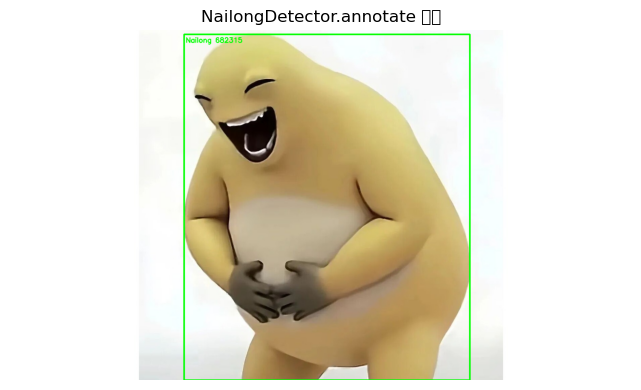

In [17]:
# --- 任务 6 img6 = cv2.imread('res/nl_hd01.jpg')测试 ---
# TODO: 构造实例，打印在 hd01 上的目标数
# TODO: set_roi(0, 540, 1920, 540) 后再打印一次
# TODO: 写一个 JSON 配置，用 from_config 读进来验证
import json
img6 = cv2.imread('res/nl_hd01.jpg')

# ① 全图检测
det = NailongDetector(lower=(15, 60, 60), upper=(48, 255, 255))
full = det.detect(img6)
print(f'① 全图检出目标数 = {len(full)}')
for r in full:
    print('   (x, y, w, h, area) =', r)

# ② 只在画面下半部分检测
det.set_roi(0, 540, 1920, 540)
print(f'② set_roi(0, 540, 1920, 540) 后检出目标数 = {len(det.detect(img6))}')
for r in det.detect(img6):
    print('   (x, y, w, h, area) =', r)

# ③ 从 JSON 读阈值构造实例
cfg = {'lower': [15, 60, 60], 'upper': [48, 255, 255], 'min_area': 2000, 'kernel_size': 7}

cfg = {'lower': [15, 60, 60], 'upper': [48, 255, 255], 'min_area': 2000, 'kernel_size': 7}
with open('out/hw6_config.json', 'w', encoding='utf-8') as fp:
    json.dump(cfg, fp)



det_cfg = NailongDetector.from_config('out/hw6_config.json')
print('③ from_config 构造成功，检出目标数 =', len(det_cfg.detect(img6)))
print('   私有属性:', [k for k in det_cfg.__dict__])


before = img6.copy()
vis6 = det_cfg.annotate(img6)
print('④ annotate 没改动原图:', np.array_equal(img6, before))
# show(vis6, titles=['NailongDetector.annotate 结果'])

**回答（为什么 set_roi 后坐标要加回偏移）：**

*roi切片后重新记录坐标，如果要回到原来的位置，需要加上偏置*

---


## 实验小结（100~200 字）

*修饰器这一块还是不太懂*